# Task 2


In [ ]:
 # imports
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import math
import itertools
import time

In [2]:
#constants
m = 1.0 # mass
mu = 5 # friction constant
k = 500 # spring constant

omega_intial = np.sqrt(k)
delta = mu/(2*m)
omega = np.sqrt(omega_intial**2 - delta**2)

def A(phi):
    return 1 / (2*math.cos(phi))

phi = np.arctan(-1*delta/omega)

print(np.exp(-1*delta*1))
print("delta =, ", delta)
print("A(phi) = ", A(phi))
print("phi = ", phi)
print("omega = ", omega)

def x(t):
    return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


0.0820849986238988
delta =,  2.5
A(phi) =  0.5031546054266276
phi =  -0.11203764265090964
omega =  22.22048604328897


## Task 2.1

In [3]:
t_train = torch.linspace(start = 0, end = 0.5, steps = 10)
t_train = t_train.view(-1,1) # We transform it into shape (samples, features), instead of (samples). In our case that is (10,1)

y_train = x(t_train)


C:\Users\Saads\AppData\Local\Temp\ipykernel_31596\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


## Task 2.2

In [4]:
class Net(nn.Module):
    def __init__(self):
        super(Net,self).__init__()
        activation = nn.Tanh()
        self.net = nn.Sequential(
            nn.Linear(1, 10),
            activation,
            nn.Linear(10, 1),
        )

    def forward(self, x):
        return self.net(x)

In [5]:
model = Net()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

num_epoch = 10000
model.train()
for epoch in range(num_epoch):
    optimizer.zero_grad()
    outputs = model(t_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    if (epoch+1) % 1000 == 0:
        print(f'Epoch [{epoch+1}/{num_epoch}], Loss: {loss.item():.4f}')

Epoch [1000/10000], Loss: 0.0463
Epoch [2000/10000], Loss: 0.0114
Epoch [3000/10000], Loss: 0.0003
Epoch [4000/10000], Loss: 0.0001
Epoch [5000/10000], Loss: 0.0000
Epoch [6000/10000], Loss: 0.0000
Epoch [7000/10000], Loss: 0.0000
Epoch [8000/10000], Loss: 0.0000
Epoch [9000/10000], Loss: 0.0000
Epoch [10000/10000], Loss: 0.0000


torch.Size([100, 1]) torch.Size([100, 1]) torch.Size([100, 1])


C:\Users\Saads\AppData\Local\Temp\ipykernel_31596\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


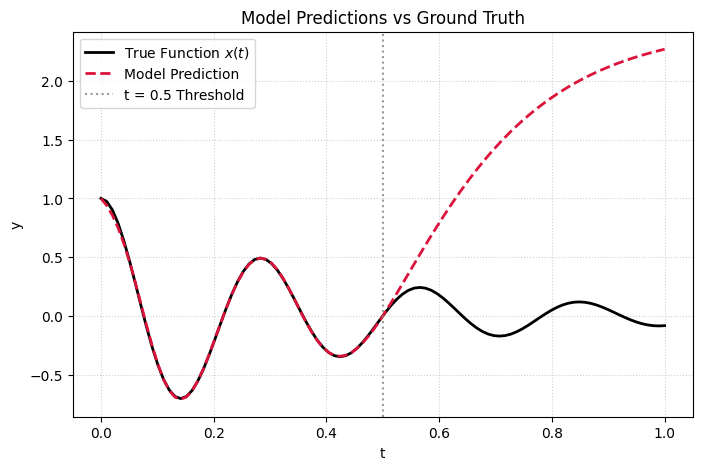

In [6]:
model.eval()

with torch.no_grad():
    t_test = torch.linspace(0, 1, 100).view(-1, 1)
    y_pred = model(t_test)
    y_true = x(t_test)

    print(t_test.shape,y_pred.shape, y_true.shape)


t_np = t_test.cpu().numpy()
y_pred_np = y_pred.cpu().numpy()
y_true_np = y_true.cpu().numpy()

# Initialize the plot
plt.figure(figsize=(8, 5))

# Plot the true values vs predictions
plt.plot(t_np, y_true_np, label='True Function $x(t)$', color='black', linewidth=2)
plt.plot(t_np, y_pred_np, label='Model Prediction', color='crimson', linestyle='--', linewidth=2)
plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.8, label='t = 0.5 Threshold')

# Metadata & Styling
plt.title('Model Predictions vs Ground Truth')
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


# Render
plt.show()





In [7]:
loss = criterion(y_pred, y_true)
print(f'Test Loss: {loss.item():.4f}')

Test Loss: 1.3355


## Task 2.3

In [8]:
net = Net().double()


In [9]:

# data points and collocation points
t_data = np.linspace(0, 0.5, 10)
x_data = x(t_data)
t_col = np.linspace(0, 1, 50)

lam_phys = 1e-4
lam_ic = 1

def NN(t, W1, b1, W2, b2):
    return np.sum(W2 * np.tanh(W1*t + b1)) + b2

def dNN(t, W1, b1, W2, b2):
    return np.sum(W2 * W1 * (1 - np.tanh(W1*t + b1)**2))

def ddNN(t, W1, b1, W2, b2):
    tanh = np.tanh(W1*t + b1)
    return np.sum(-2 * W2 * W1**2 * tanh * (1 - tanh**2))

def loss_terms(W1, b1, W2, b2):
  # data term
  L_data = 0
  for i in range(len(t_data)):
      L_data += (NN(t_data[i], W1, b1, W2, b2) - x_data[i])**2
  L_data = L_data / len(t_data)

  # physics term
  L_phys = 0
  for i in range(len(t_col)):
      t = t_col[i]
      r = ddNN(t, W1, b1, W2, b2) + mu/m * dNN(t, W1, b1, W2, b2) + k/m * NN(t, W1, b1, W2, b2)
      L_phys += r**2
  L_phys = L_phys / len(t_col)

  # initial conditions
  L_ic = (NN(0, W1, b1, W2, b2) - 1)**2 + (dNN(0, W1, b1, W2, b2) - 0)**2

  return L_data, L_phys, L_ic

def loss(W1, b1, W2, b2, lam_phys=lam_phys, lam_ic=lam_ic):
  L_data, L_phys, L_ic = loss_terms(W1, b1, W2, b2)
  return L_data + lam_phys*L_phys + lam_ic*L_ic





def gradients(W1, b1, W2, b2, lam_phys=lam_phys, lam_ic=lam_ic):
    dW1 = np.zeros(len(W1))
    db1 = np.zeros(len(b1))
    dW2 = np.zeros(len(W2))
    db2 = 0

    # data term
    for i in range(len(t_data)):
        t = t_data[i]
        tanh = np.tanh(W1*t + b1)
        e = NN(t, W1, b1, W2, b2) - x_data[i]

        dW1 += 2/len(t_data) * e * W2 * (1 - tanh**2) * t
        db1 += 2/len(t_data) * e * W2 * (1 - tanh**2)
        dW2 += 2/len(t_data) * e * tanh
        db2 += 2/len(t_data) * e

    # physics term
    for i in range(len(t_col)):
        t = t_col[i]
        tanh = np.tanh(W1*t + b1)
        r = ddNN(t, W1, b1, W2, b2) + mu/m * dNN(t, W1, b1, W2, b2) + k/m * NN(t, W1, b1, W2, b2)

        # eq (42)
        dr_dW1 = (-4 * W2 * W1 * tanh * (1 - tanh**2)
                  - 2 * W2 * W1**2 * t * (1 - tanh**2)**2
                  + 4 * W2 * W1**2 * t * tanh**2 * (1 - tanh**2)
                  + mu/m * (W2 * (1 - tanh**2) - 2 * W2 * W1 * t * tanh * (1 - tanh**2))
                  + k/m * W2 * t * (1 - tanh**2))

        # eq (43)
        dr_dW2 = (-2 * W1**2 * tanh * (1 - tanh**2)
                  + mu/m * W1 * (1 - tanh**2)
                  + k/m * tanh)

        # biases: same as for W1 but without the factor t from the inner derivative
        dr_db1 = (-2 * W2 * W1**2 * (1 - tanh**2)**2
                  + 4 * W2 * W1**2 * tanh**2 * (1 - tanh**2)
                  + mu/m * (-2 * W2 * W1 * tanh * (1 - tanh**2))
                  + k/m * W2 * (1 - tanh**2))
        dr_db2 = k/m

        dW1 += lam_phys * 2/len(t_col) * r * dr_dW1
        db1 += lam_phys * 2/len(t_col) * r * dr_db1
        dW2 += lam_phys * 2/len(t_col) * r * dr_dW2
        db2 += lam_phys * 2/len(t_col) * r * dr_db2

    # initial conditions (t = 0)
    tanh0 = np.tanh(b1)
    NN0 = NN(0, W1, b1, W2, b2)
    dNN0 = dNN(0, W1, b1, W2, b2)

    dW1 += lam_ic * 2 * dNN0 * W2 * (1 - tanh0**2)
    db1 += lam_ic * (2 * (NN0 - 1) * W2 * (1 - tanh0**2) - 4 * dNN0 * W2 * W1 * tanh0 * (1 - tanh0**2))
    dW2 += lam_ic * (2 * (NN0 - 1) * tanh0 + 2 * dNN0 * W1 * (1 - tanh0**2))
    db2 += lam_ic * 2 * (NN0 - 1)

    return dW1, db1, dW2, db2

## Task 2.4

In [10]:
def get_params(model):
    W1 = model.net[0].weight.detach().numpy()[:, 0]
    b1 = model.net[0].bias.detach().numpy()
    W2 = model.net[2].weight.detach().numpy()[0, :]
    b2 = model.net[2].bias.detach().numpy()[0]
    return W1, b1, W2, b2

def rel_error(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)

def fd_grad_W1(W1, b1, W2, b2, lam_p=lam_phys, lam_i=lam_ic, epsilon=10 ** -5):
    dW1_fd = np.zeros(len(W1))
    for j in range(len(W1)):
        W1_minus = W1.copy()
        W1_minus[j] -= epsilon
        W1_plus = W1.copy()
        W1_plus[j] += epsilon
        dW1_fd[j] = (loss(W1_plus, b1, W2, b2, lam_p, lam_i) - loss(W1_minus, b1, W2, b2, lam_p, lam_i)) / (2*epsilon)
    return dW1_fd


torch.manual_seed(0)
net = Net().double()
W1, b1, W2, b2 = get_params(net)

dW1, db1, dW2, db2 = gradients(W1, b1, W2, b2)
dW1_fd = fd_grad_W1(W1, b1, W2, b2)

print(dW1)
print(dW1_fd)
print(" error:", rel_error(dW1, dW1_fd))

[-0.55689453 -1.33715128  0.06807861 -0.43738516  0.17951606 -0.16942355
 -1.32068953  0.56647116  0.64322223  0.39630643]
[-0.55689453 -1.33715128  0.06807861 -0.43738516  0.17951606 -0.16942355
 -1.32068953  0.56647116  0.64322223  0.39630643]
 error: 2.648413886451801e-11


## Task 2.5


In [11]:
# Training loop

Epoch = 20000
optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
losses = []
data_losses, phys_losses, ic_losses = [], [], []

for i in range(Epoch):
  # Loss function  where the forward pass also happens
  W1, b1, W2, b2 = get_params(net)

  L_data, L_phys, L_ic = loss_terms(W1, b1, W2, b2)
  losses.append(L_data + lam_phys*L_phys + lam_ic*L_ic)
  data_losses.append(L_data)
  phys_losses.append(L_phys)
  ic_losses.append(L_ic)

  # Update weights
  dW1,db1, dW2, db2= gradients(W1,b1,W2,b2) # compute gradient

  # Our parameters are converted in torch again, in order to use the ADAM Optimizer.
  net.net[0].weight.grad = torch.tensor(dW1).reshape(10, 1)
  net.net[0].bias.grad = torch.tensor(db1)
  net.net[2].weight.grad = torch.tensor(dW2).reshape(1, 10)
  net.net[2].bias.grad = torch.tensor([db2],dtype=torch.float64)

  optimizer.step()

  if i % 1000 == 0:
      print(i, losses[-1])

0 2.6264649670255236
1000 0.8991107151588918
2000 0.3313747098190789
3000 0.19231572145813525
4000 0.10770086161100055
5000 0.05747259578894022
6000 0.052414050993420426
7000 0.05011308379573744
8000 0.04951876342876764
9000 0.04551666764934811
10000 0.04388028521929803
11000 0.04146747418706369
12000 0.039770327585922326
13000 0.03831297092794893
14000 0.03705561752734804
15000 0.03592024155121677
16000 0.03486348420651932
17000 0.03385018086088418
18000 0.03286682798550914
19000 0.031916050748855555


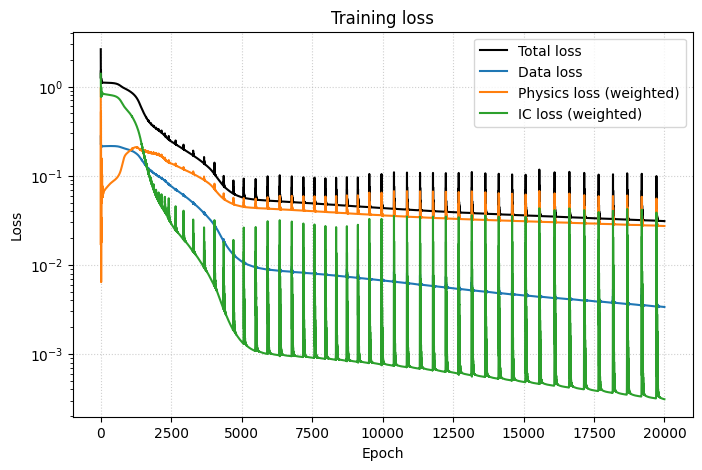

In [12]:
plt.figure(figsize=(8, 5))
plt.semilogy(losses, label='Total loss', color='black')
plt.semilogy(data_losses, label='Data loss')
plt.semilogy(lam_phys*np.array(phys_losses), label='Physics loss (weighted)')
plt.semilogy(lam_ic*np.array(ic_losses), label='IC loss (weighted)')
plt.title('Training loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [13]:
# Our settings for the sweep (20000 for final pass)
torch.set_default_dtype(torch.float64)
EPOCHS = 5000
LR = 0.01
SEEDS = [0, 1, 2]
# Logarithmic spacing from 10^-3 to 10^-1
LAM_PHYS_GRID = np.logspace(-3, -1, num=5)
# Logarithmic spacing from 10^-2 to 10^3, with 0 prepended
LAM_IC_GRID = np.insert(np.logspace(-2, 3, num=6), 0, 0.0)

# Evaluation grid on (0,1), extrapolation part is t > 0.5
t_eval = torch.linspace(0, 1, 200).view(-1, 1)
x_eval = x(t_eval)
mask_extrap = (t_eval[:, 0] > 0.5)

def train(lam_p, lam_i, seed, epochs=EPOCHS):
    torch.manual_seed(seed)
    model = Net().double()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    losses = []

    for i in range(epochs):
        # Loss function  where the forward pass also happens
        W1, b1, W2, b2 = get_params(model)

        losses.append(loss(W1, b1, W2, b2, lam_p, lam_i))

        # Update weights
        dW1,db1, dW2, db2= gradients(W1, b1, W2, b2, lam_p, lam_i) # compute gradient

        # Our parameters are converted in torch again, in order to use the ADAM Optimizer.
        model.net[0].weight.grad = torch.tensor(dW1).reshape(10, 1)
        model.net[0].bias.grad = torch.tensor(db1)
        model.net[2].weight.grad = torch.tensor(dW2).reshape(1, 10)
        model.net[2].bias.grad = torch.tensor([db2],dtype=torch.float64)

        optimizer.step()

    with torch.no_grad():
        err = (model(t_eval) - x_eval) ** 2
        return model, err.mean().item(), err[mask_extrap].mean().item(), losses

C:\Users\Saads\AppData\Local\Temp\ipykernel_31596\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


In [14]:
# The sweep to check all combinations
results = []
for lp, li in itertools.product(LAM_PHYS_GRID, LAM_IC_GRID):
    runs = [train(lp, li, s)[1:3] for s in SEEDS]
    full = np.array([r[0] for r in runs])
    extrap = np.array([r[1] for r in runs])
    results.append((lp, li, np.median(full), full.max(), np.median(extrap)))
    print(f"lam_phys={lp:<7g} lam_ic={li:<5g} "
          f"median_full={np.median(full):.3e} worst={full.max():.3e} "
          f"median_extrap={np.median(extrap):.3e}", flush=True)

results.sort(key=lambda r: r[2])
print("\nTop 5 (lam_phys, lam_ic, median_full_MSE, worst_MSE, median_extrap_MSE):")
for r in results[:5]:
    print(f"  {r[0]:<7g} {r[1]:<5g} {r[2]:.3e} {r[3]:.3e} {r[4]:.3e}")

lam_phys=0.001   lam_ic=0     median_full=1.061e-01 worst=1.062e-01 median_extrap=1.507e-02
lam_phys=0.001   lam_ic=0.01  median_full=1.060e-01 worst=1.062e-01 median_extrap=1.507e-02
lam_phys=0.001   lam_ic=0.1   median_full=1.059e-01 worst=1.061e-01 median_extrap=1.508e-02
lam_phys=0.001   lam_ic=1     median_full=1.054e-01 worst=1.055e-01 median_extrap=1.522e-02
lam_phys=0.001   lam_ic=10    median_full=2.212e-02 worst=4.302e-02 median_extrap=1.827e-02
lam_phys=0.001   lam_ic=100   median_full=4.765e-02 worst=6.182e-02 median_extrap=1.462e-02
lam_phys=0.001   lam_ic=1000  median_full=9.359e-02 worst=9.942e-02 median_extrap=1.363e-02
lam_phys=0.00316228 lam_ic=0     median_full=1.062e-01 worst=1.063e-01 median_extrap=1.505e-02
lam_phys=0.00316228 lam_ic=0.01  median_full=1.062e-01 worst=1.063e-01 median_extrap=1.505e-02
lam_phys=0.00316228 lam_ic=0.1   median_full=1.062e-01 worst=1.063e-01 median_extrap=1.506e-02
lam_phys=0.00316228 lam_ic=1     median_full=1.058e-01 worst=1.059e-01 

weak   lam_phys = 1e-05  MSE: 0.041899630984314463  MSE t>0.5: 0.019767588317105088
strong lam_phys = 0.001  MSE: 0.009014799733211067  MSE t>0.5: 0.01409795627305134


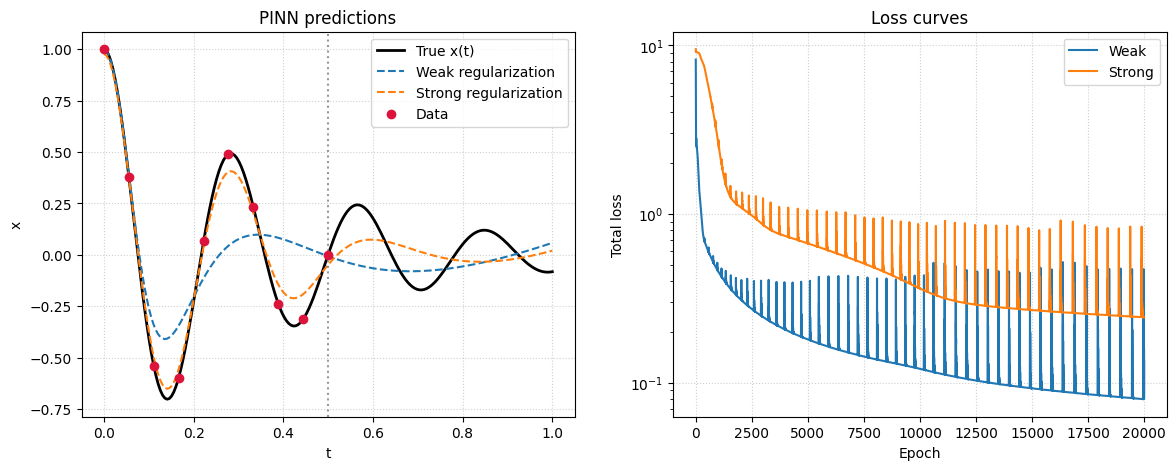

In [15]:
# weak vs strong regularization, same seed and lam_ic
lam_p_best = results[0][0]
lam_i_best = results[0][1]
lam_p_weak = 1e-5

model_weak, mse_weak, extrap_weak, losses_weak = train(lam_p_weak, lam_i_best, seed=0, epochs=20000)
model_strong, mse_strong, extrap_strong, losses_strong = train(lam_p_best, lam_i_best, seed=0, epochs=20000)

print("weak   lam_phys =", lam_p_weak, " MSE:", mse_weak, " MSE t>0.5:", extrap_weak)
print("strong lam_phys =", lam_p_best, " MSE:", mse_strong, " MSE t>0.5:", extrap_strong)

with torch.no_grad():
    x_weak = model_weak(t_eval).numpy()
    x_strong = model_strong(t_eval).numpy()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(t_eval.numpy(), x_eval.numpy(), label='True x(t)', color='black', linewidth=2)
ax[0].plot(t_eval.numpy(), x_weak, '--', label='Weak regularization')
ax[0].plot(t_eval.numpy(), x_strong, '--', label='Strong regularization')
ax[0].scatter(t_data, x_data, color='crimson', zorder=3, label='Data')
ax[0].axvline(x=0.5, color='gray', linestyle=':', alpha=0.8)
ax[0].set_xlabel('t')
ax[0].set_ylabel('x')
ax[0].set_title('PINN predictions')
ax[0].legend()
ax[0].grid(True, linestyle=':', alpha=0.6)

ax[1].semilogy(losses_weak, label='Weak')
ax[1].semilogy(losses_strong, label='Strong')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Total loss')
ax[1].set_title('Loss curves')
ax[1].legend()
ax[1].grid(True, linestyle=':', alpha=0.6)

plt.show()

## Task 2.6

In [16]:
lam_p = 0.001
lam_i = 0

t_data_t = torch.tensor(t_data).view(-1, 1)
x_data_t = torch.tensor(x_data).view(-1, 1)
t_col_t = torch.tensor(t_col).view(-1, 1).requires_grad_(True)
t0 = torch.zeros(1, 1, dtype=torch.float64, requires_grad=True)

def torch_loss(model, lam_p, lam_i):
    L_data = torch.mean((model(t_data_t) - x_data_t)**2)

    # x' and x'' wrt t at the collocation points
    x_col = model(t_col_t)
    dx = torch.autograd.grad(x_col, t_col_t, torch.ones_like(x_col), create_graph=True)[0]
    ddx = torch.autograd.grad(dx, t_col_t, torch.ones_like(dx), create_graph=True)[0]
    L_phys = torch.mean((ddx + mu/m * dx + k/m * x_col)**2)

    x0 = model(t0)
    dx0 = torch.autograd.grad(x0, t0, torch.ones_like(x0), create_graph=True)[0]
    L_ic = ((x0 - 1)**2 + dx0**2).squeeze()

    return L_data + lam_p*L_phys + lam_i*L_ic


# Gradient check at initialization, lam_ic = 1 here so the IC term is also checked
torch.manual_seed(0)
net_auto = Net().double()
W1, b1, W2, b2 = get_params(net_auto)

dW1, db1, dW2, db2 = gradients(W1, b1, W2, b2, lam_p, 1)

L = torch_loss(net_auto, lam_p, 1)
grads = torch.autograd.grad(L, net_auto.parameters())

dW1_auto = grads[0].detach().numpy()[:, 0]
db1_auto = grads[1].detach().numpy()
dW2_auto = grads[2].detach().numpy()[0, :]
db2_auto = grads[3].detach().numpy()[0]

print("loss hand:", loss(W1, b1, W2, b2, lam_p, 1), " loss autograd:", L.item())
print("W1 rel error:", rel_error(dW1, dW1_auto))
print("b1 rel error:", rel_error(db1, db1_auto))
print("W2 rel error:", rel_error(dW2, dW2_auto))
print("b2 rel error:", rel_error(db2, db2_auto))

g_hand = np.concatenate([dW1, db1, dW2, [db2]])
g_auto = np.concatenate([dW1_auto, db1_auto, dW2_auto, [db2_auto]])
print("total rel error:", rel_error(g_hand, g_auto))

# also compare both against finite differences for W1
dW1_fd = fd_grad_W1(W1, b1, W2, b2, lam_p, 1)
print("W1 hand vs FD:", rel_error(dW1, dW1_fd))
print("W1 autograd vs FD:", rel_error(dW1_auto, dW1_fd))

loss hand: 2.2804821137188123  loss autograd: 2.2804821137188123
W1 rel error: 3.9926641226597587e-16
b1 rel error: 2.1956995523001376e-16
W2 rel error: 2.448816145857695e-16
b2 rel error: 4.4199879868575473e-16
total rel error: 3.3304640124501594e-16
W1 hand vs FD: 5.011477922895755e-11
W1 autograd vs FD: 5.0114779626232e-11


time hand: 134.71119713783264 s, time autograd: 32.045039653778076 s
final loss hand: 0.22334647784772052  autograd: 0.22334326054344197
max loss diff: 0.0612222762106748
max prediction diff: 4.0253217840541256e-05


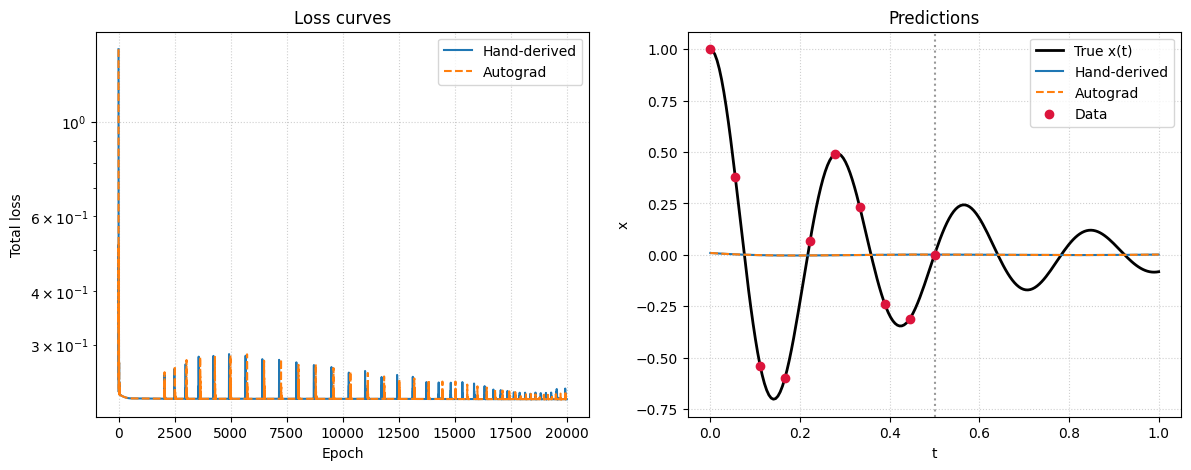

In [17]:
def train_auto(lam_p, lam_i, seed, epochs=EPOCHS):
    torch.manual_seed(seed)
    model = Net().double()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    losses = []
    for i in range(epochs):
        optimizer.zero_grad()
        L = torch_loss(model, lam_p, lam_i)

        grads = torch.autograd.grad(L, model.parameters())
        model.net[0].weight.grad = grads[0]
        model.net[0].bias.grad = grads[1]
        model.net[2].weight.grad = grads[2]
        model.net[2].bias.grad = grads[3]

        optimizer.step()
        losses.append(L.item())

    return model, losses


num_epoch = 20000

start = time.time()
model_hand, _, _, losses_hand = train(lam_p, lam_i, seed=0, epochs=num_epoch)
time_hand = time.time() - start

start = time.time()
model_auto, losses_auto = train_auto(lam_p, lam_i, seed=0, epochs=num_epoch)
time_auto = time.time() - start

with torch.no_grad():
    x_hand = model_hand(t_eval).numpy()
    x_auto = model_auto(t_eval).numpy()

print("time hand:", time_hand, "s, time autograd:", time_auto, "s")
print("final loss hand:", losses_hand[-1], " autograd:", losses_auto[-1])
print("max loss diff:", np.max(np.abs(np.array(losses_hand) - np.array(losses_auto))))
print("max prediction diff:", np.max(np.abs(x_hand - x_auto)))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].semilogy(losses_hand, label='Hand-derived')
ax[0].semilogy(losses_auto, '--', label='Autograd')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Total loss')
ax[0].set_title('Loss curves')
ax[0].legend()
ax[0].grid(True, linestyle=':', alpha=0.6)

ax[1].plot(t_eval.numpy(), x_eval.numpy(), label='True x(t)', color='black', linewidth=2)
ax[1].plot(t_eval.numpy(), x_hand, label='Hand-derived')
ax[1].plot(t_eval.numpy(), x_auto, '--', label='Autograd')
ax[1].scatter(t_data, x_data, color='crimson', zorder=3, label='Data')
ax[1].axvline(x=0.5, color='gray', linestyle=':', alpha=0.8)
ax[1].set_xlabel('t')
ax[1].set_ylabel('x')
ax[1].set_title('Predictions')
ax[1].legend()
ax[1].grid(True, linestyle=':', alpha=0.6)

plt.show()